In [358]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [359]:
from pathlib import Path
# dataset = "train" 
dataset = "test"

data_files = {
    "train": Path("./data/train_dataset.csv"),
    "test": Path("./data/test_without_gt.csv"),
}

if dataset not in data_files:
    raise ValueError('dataset ต้องเป็น "train" หรือ "test"')

file_path = data_files[dataset]
df = pd.read_csv(file_path, dtype={"ID": "string"})

print(f"Loaded {dataset} from {file_path} | {len(df):,} rows")

Loaded test from data\test_without_gt.csv | 137,091 rows


In [360]:
pd.set_option('display.max_columns', 60)

In [361]:
df.head()

,ID,Application Channel,Gender,Marital Status,Age (in months),Residence Period (in months),Occupation Category,Industry Category,Employment Type Category,Insurance Type,Company Size Category,Business Entity Type,Declared Annual Income,Payday,Declared Number of Borrowings,Declared Borrowing Amount,Desired Credit Limit,Residence Type,Rent Burden,Residence Ownership Status,Number of Dependents,Number of Dependent Children,Home Phone Number Available,Mobile Phone Number Available,Employer Phone Number Available,Driver Licence Number Available
0,211850001,20,1,1,301,301,640,1,1,1,3,0,3000000,10,0,0,200000,1,0,1,0,0,1,1,1,0
1,211850002,20,1,2,274,15,640,5,1,1,5,0,2700000,10,0,0,200000,1,40000,1,1,1,0,1,1,0
2,211850003,20,1,2,771,28,640,99,4,1,5,0,1500000,25,0,0,500000,4,50000,0,0,0,0,1,1,1
3,211870001,17,1,2,370,26,640,5,1,1,5,9,4200000,15,2,1000000,200000,4,54000,0,1,1,0,1,1,1
4,211880001,17,2,1,270,1,540,1,5,1,4,9,1400000,31,2,400000,150000,4,48000,0,0,0,0,1,1,0


In [362]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 137091 entries, 0 to 137090
Data columns (total 26 columns):
 #   Column                           Non-Null Count   Dtype 
---  ------                           --------------   ----- 
 0   ID                               137091 non-null  string
 1   Application Channel              137091 non-null  int64 
 2   Gender                           137091 non-null  int64 
 3   Marital Status                   137091 non-null  int64 
 4   Age (in months)                  137091 non-null  int64 
 5   Residence Period (in months)     137091 non-null  int64 
 6   Occupation Category              137091 non-null  int64 
 7   Industry Category                137091 non-null  int64 
 8   Employment Type Category         137091 non-null  int64 
 9   Insurance Type                   137091 non-null  int64 
 10  Company Size Category            137091 non-null  int64 
 11  Business Entity Type             137091 non-null  int64 
 12  Declared Annual Income     

## Declair data type 

In [363]:
df['Gender'] = df['Gender'].map({1:1,2:0})
df.rename(columns={'Gender' : 'Is_male'},inplace=True)

df['Marital Status'] = df['Marital Status'].map({1:0,2:1})
df.rename(columns={'Marital Status' : 'Is_married'},inplace=True)

In [364]:
category_cols = {'Application Channel','Occupation Category',
                 'Industry Category','Employment Type Category','Insurance Type',
                 'Company Size Category','Business Entity Type','Residence Type','Residence Ownership Status',
                 }

boolean_cols = {'Is_male','Is_married','Home Phone Number Available','Mobile Phone Number Available',
                'Employer Phone Number Available','Driver Licence Number Available'}

df = df.astype({
    **dict.fromkeys(category_cols, "category"),
    **dict.fromkeys(boolean_cols, "boolean"),
})


## Cut data

In [365]:
df.columns

Index(['ID', 'Application Channel', 'Is_male', 'Is_married', 'Age (in months)',
       'Residence Period (in months)', 'Occupation Category',
       'Industry Category', 'Employment Type Category', 'Insurance Type',
       'Company Size Category', 'Business Entity Type',
       'Declared Annual Income', 'Payday', 'Declared Number of Borrowings',
       'Declared Borrowing Amount', 'Desired Credit Limit', 'Residence Type',
       'Rent Burden', 'Residence Ownership Status', 'Number of Dependents',
       'Number of Dependent Children', 'Home Phone Number Available',
       'Mobile Phone Number Available', 'Employer Phone Number Available',
       'Driver Licence Number Available'],
      dtype='str')

In [366]:
df['Residence_Age'] = (df['Residence Period (in months)']/12).astype(int)

df['Age'] = (df['Age (in months)']/12).astype(int)

##cut

df["Residence_age_bins"] = pd.cut(
    df["Residence_Age"],
    bins=[0, 1, 5, 10, 20,40,60, float("inf")],
    labels=["Under 1 year", "1–5 years", "5–10 years",
            "10–20 years", "20-40 years","40-60 years","60+ years"],
)

df["Age_bins"] = pd.cut(
    df['Age'],
    bins=[0, 25, 35, 45, 55, 65, float("inf")],
    labels=["Under 25", "25–34", "35–44", "45–54", "55–64", "65+"]
)

df["Payday_Period"] = pd.cut(
    df['Payday'],
    bins=[0, 10, 20, 31],
    labels=["Early_month", "Mid_month", "Late_month"],
)

df.drop(columns=['Payday','Age (in months)','Residence Period (in months)'],inplace=True)

category_cols.update(['Payday_Period','Age_bins','Residence_age_bins'])

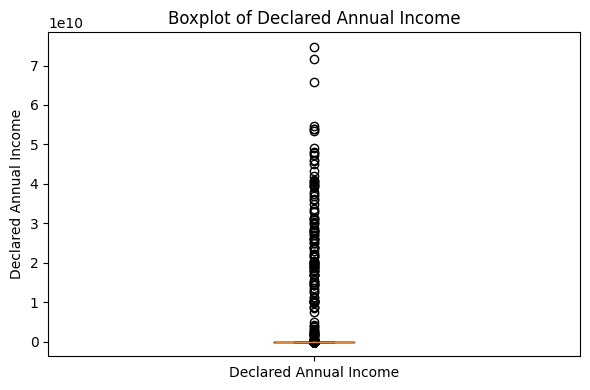

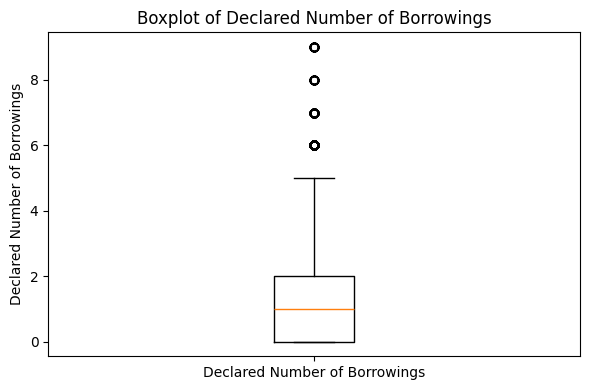

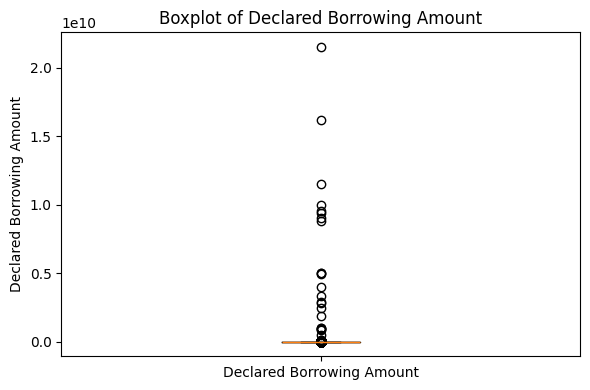

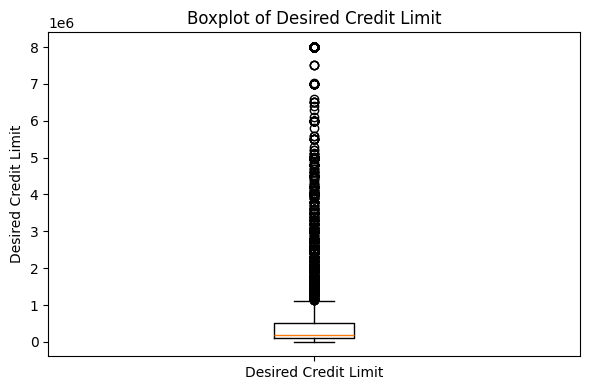

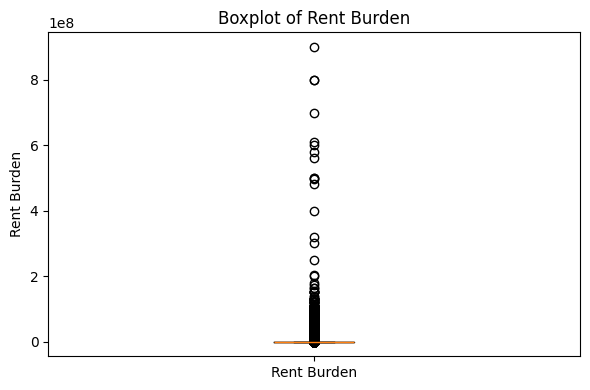

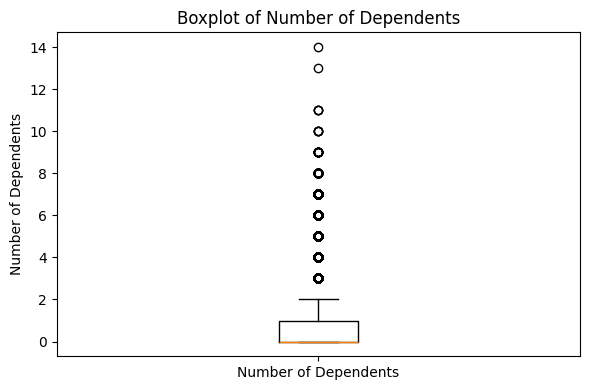

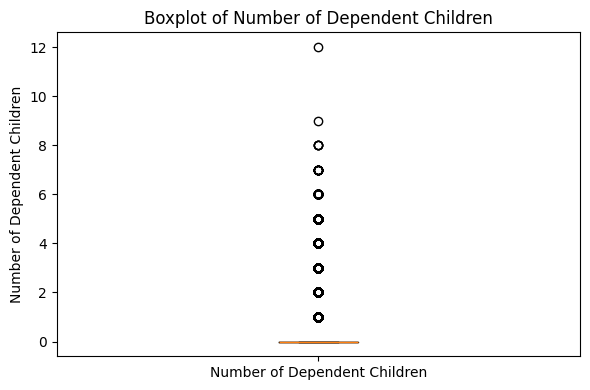

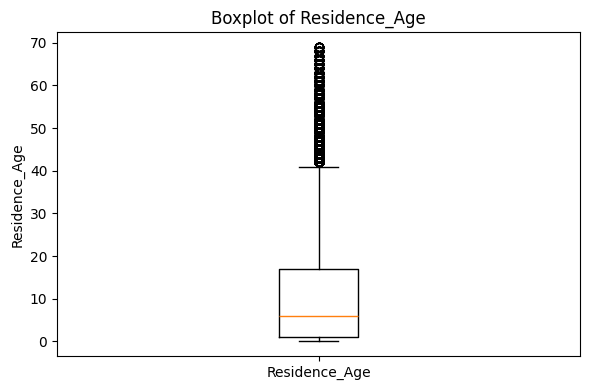

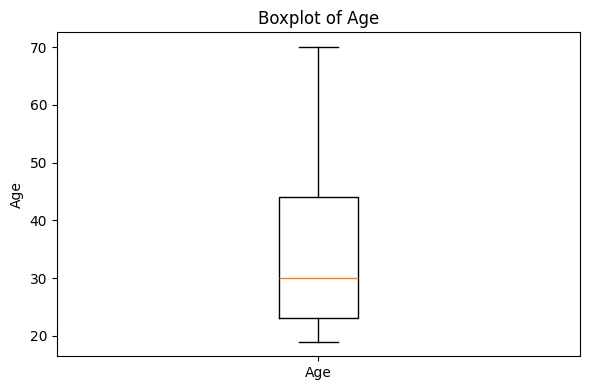

In [367]:
import matplotlib.pyplot as plt

numeric_columns = df.select_dtypes(include="number").columns

for column in numeric_columns:
    values = df[column].dropna()
    if values.empty:
        continue

    plt.figure(figsize=(6, 4))
    plt.boxplot(values)
    plt.xticks([1], [column])
    plt.ylabel(column)
    plt.title(f"Boxplot of {column}")
    plt.tight_layout()
    plt.show()

## Log for skew data

In [368]:
log_cols = [
    "Declared Annual Income",
    "Rent Burden",
    "Desired Credit Limit",
]

values = df[log_cols].apply(pd.to_numeric, errors="raise")

negative_cols = values.columns[values.lt(0).any()].tolist()
if negative_cols:
    raise ValueError(f"ตรวจสอบค่าติดลบก่อนแปลง log: {negative_cols}")

log_values = np.log1p(values).add_prefix("Log ")
df[log_values.columns] = log_values

display(df[log_cols + log_values.columns.tolist()].head())


,Declared Annual Income,Rent Burden,Desired Credit Limit,Log Declared Annual Income,Log Rent Burden,Log Desired Credit Limit
0,3000000,0,200000,14.914123,0.000000,12.206078
1,2700000,40000,200000,14.808763,10.596660,12.206078
2,1500000,50000,500000,14.220976,10.819798,13.122365
3,4200000,54000,200000,15.250595,10.896758,12.206078
4,1400000,48000,150000,14.151984,10.778977,11.918397


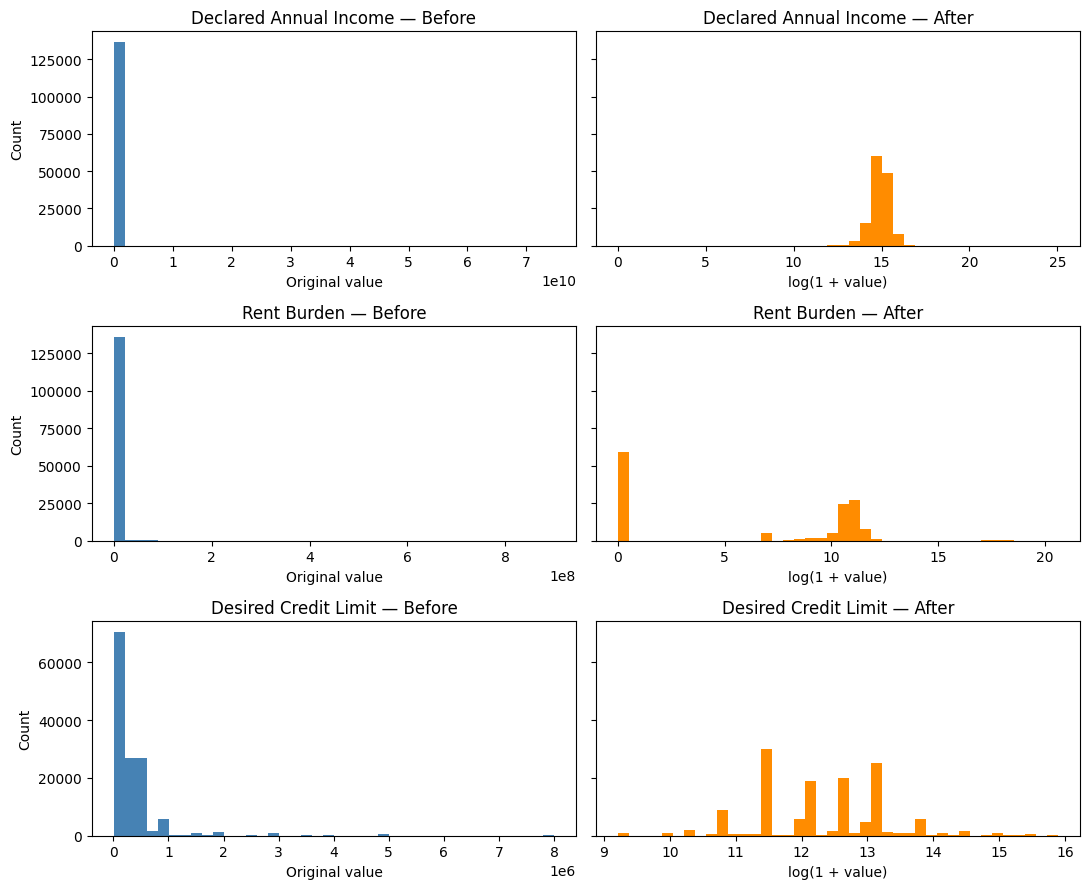

In [369]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    len(log_cols), 2,
    figsize=(11, 3 * len(log_cols)),
    sharey="row",
    squeeze=False,
)

for (ax_before, ax_after), col in zip(axes, log_cols):
    ax_before.hist(df[col].dropna(), bins=40, color="steelblue")
    ax_before.set_title(f"{col} — Before")
    ax_before.set_xlabel("Original value")
    ax_before.set_ylabel("Count")

    ax_after.hist(df[f"Log {col}"].dropna(), bins=40, color="darkorange")
    ax_after.set_title(f"{col} — After")
    ax_after.set_xlabel("log(1 + value)")

fig.tight_layout()
plt.show()

In [370]:
## There're many 0 in Rent Burden so make new bool col 
df['Has_rent'] = df['Rent Burden'] > 0

## One-hot Encoding

In [371]:
cat_cols = sorted(category_cols)
df_encoded = pd.get_dummies(df, columns=cat_cols, dtype=int,drop_first=True)

display(df_encoded.head())

,ID,Is_male,Is_married,Declared Annual Income,Declared Number of Borrowings,Declared Borrowing Amount,Desired Credit Limit,Rent Burden,Number of Dependents,Number of Dependent Children,Home Phone Number Available,Mobile Phone Number Available,Employer Phone Number Available,Driver Licence Number Available,Residence_Age,Age,Log Declared Annual Income,Log Rent Burden,Log Desired Credit Limit,Has_rent,Age_bins_25–34,Age_bins_35–44,Age_bins_45–54,Age_bins_55–64,Age_bins_65+,Application Channel_17,Application Channel_18,Application Channel_20,Business Entity Type_1,Business Entity Type_2,...,Occupation Category_240,Occupation Category_340,Occupation Category_440,Occupation Category_540,Occupation Category_640,Occupation Category_740,Occupation Category_840,Occupation Category_940,Occupation Category_1040,Occupation Category_1140,Occupation Category_1240,Occupation Category_1340,Occupation Category_1440,Occupation Category_1540,Payday_Period_Mid_month,Payday_Period_Late_month,Residence Ownership Status_1,Residence Ownership Status_2,Residence Ownership Status_3,Residence Type_2,Residence Type_3,Residence Type_4,Residence Type_5,Residence Type_6,Residence_age_bins_1–5 years,Residence_age_bins_5–10 years,Residence_age_bins_10–20 years,Residence_age_bins_20-40 years,Residence_age_bins_40-60 years,Residence_age_bins_60+ years
0,211850001,True,False,3000000,0,0,200000,0,0,0,True,True,True,False,25,25,14.914123,0.000000,12.206078,False,0,0,0,0,0,0,0,1,0,0,...,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0
1,211850002,True,True,2700000,0,0,200000,40000,1,1,False,True,True,False,1,22,14.808763,10.596660,12.206078,True,0,0,0,0,0,0,0,1,0,0,...,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0
2,211850003,True,True,1500000,0,0,500000,50000,0,0,False,True,True,True,2,64,14.220976,10.819798,13.122365,True,0,0,0,1,0,0,0,1,0,0,...,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,1,0,0,0,0,0
3,211870001,True,True,4200000,2,1000000,200000,54000,1,1,False,True,True,True,2,30,15.250595,10.896758,12.206078,True,1,0,0,0,0,1,0,0,0,0,...,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0
4,211880001,False,False,1400000,2,400000,150000,48000,0,0,False,True,True,False,0,22,14.151984,10.778977,11.918397,True,0,0,0,0,0,1,0,0,0,0,...,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0


In [372]:
df_encoded.columns

Index(['ID', 'Is_male', 'Is_married', 'Declared Annual Income',
       'Declared Number of Borrowings', 'Declared Borrowing Amount',
       'Desired Credit Limit', 'Rent Burden', 'Number of Dependents',
       'Number of Dependent Children',
       ...
       'Residence Type_3', 'Residence Type_4', 'Residence Type_5',
       'Residence Type_6', 'Residence_age_bins_1–5 years',
       'Residence_age_bins_5–10 years', 'Residence_age_bins_10–20 years',
       'Residence_age_bins_20-40 years', 'Residence_age_bins_40-60 years',
       'Residence_age_bins_60+ years'],
      dtype='str', length=101)

In [373]:
output_files = {
    "train": Path("data_preprocessed_V1.csv"),
    "test": Path("test_preprocessed_V1.csv"),
}

output_path = output_files[dataset]
df_encoded.to_csv(output_path, index=False, encoding="utf-8")

print(f"Saved {len(df_encoded):,} rows to {output_path}")

Saved 137,091 rows to test_preprocessed_V1.csv
